In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


df = pd.read_csv(os.path.join("..", "datos", "credit_risk_dataset.csv"))

## Item 1: Carga e inspección inicial de los datos
Tamaño del conjunto, tipos de variables y descripción estadística.

In [3]:
print(f"Dimensiones del dataset: filas: {df.shape[0]}, columnas: {df.shape[1]}")
print(df.dtypes)
print(df.describe(include='all'))

Dimensiones del dataset: filas: 32581, columnas: 12
person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object
          person_age  person_income person_home_ownership  person_emp_length  \
count   32581.000000   3.258100e+04                 32581       31686.000000   
unique           NaN            NaN                     4                NaN   
top              NaN            NaN                  RENT                NaN   
freq             NaN            NaN                 16446                NaN   
mean       27.734600   6.607485e+04                   NaN           4.789686  

## Item 3: Identificacion de outliders
visualizaciones tipo boxplot

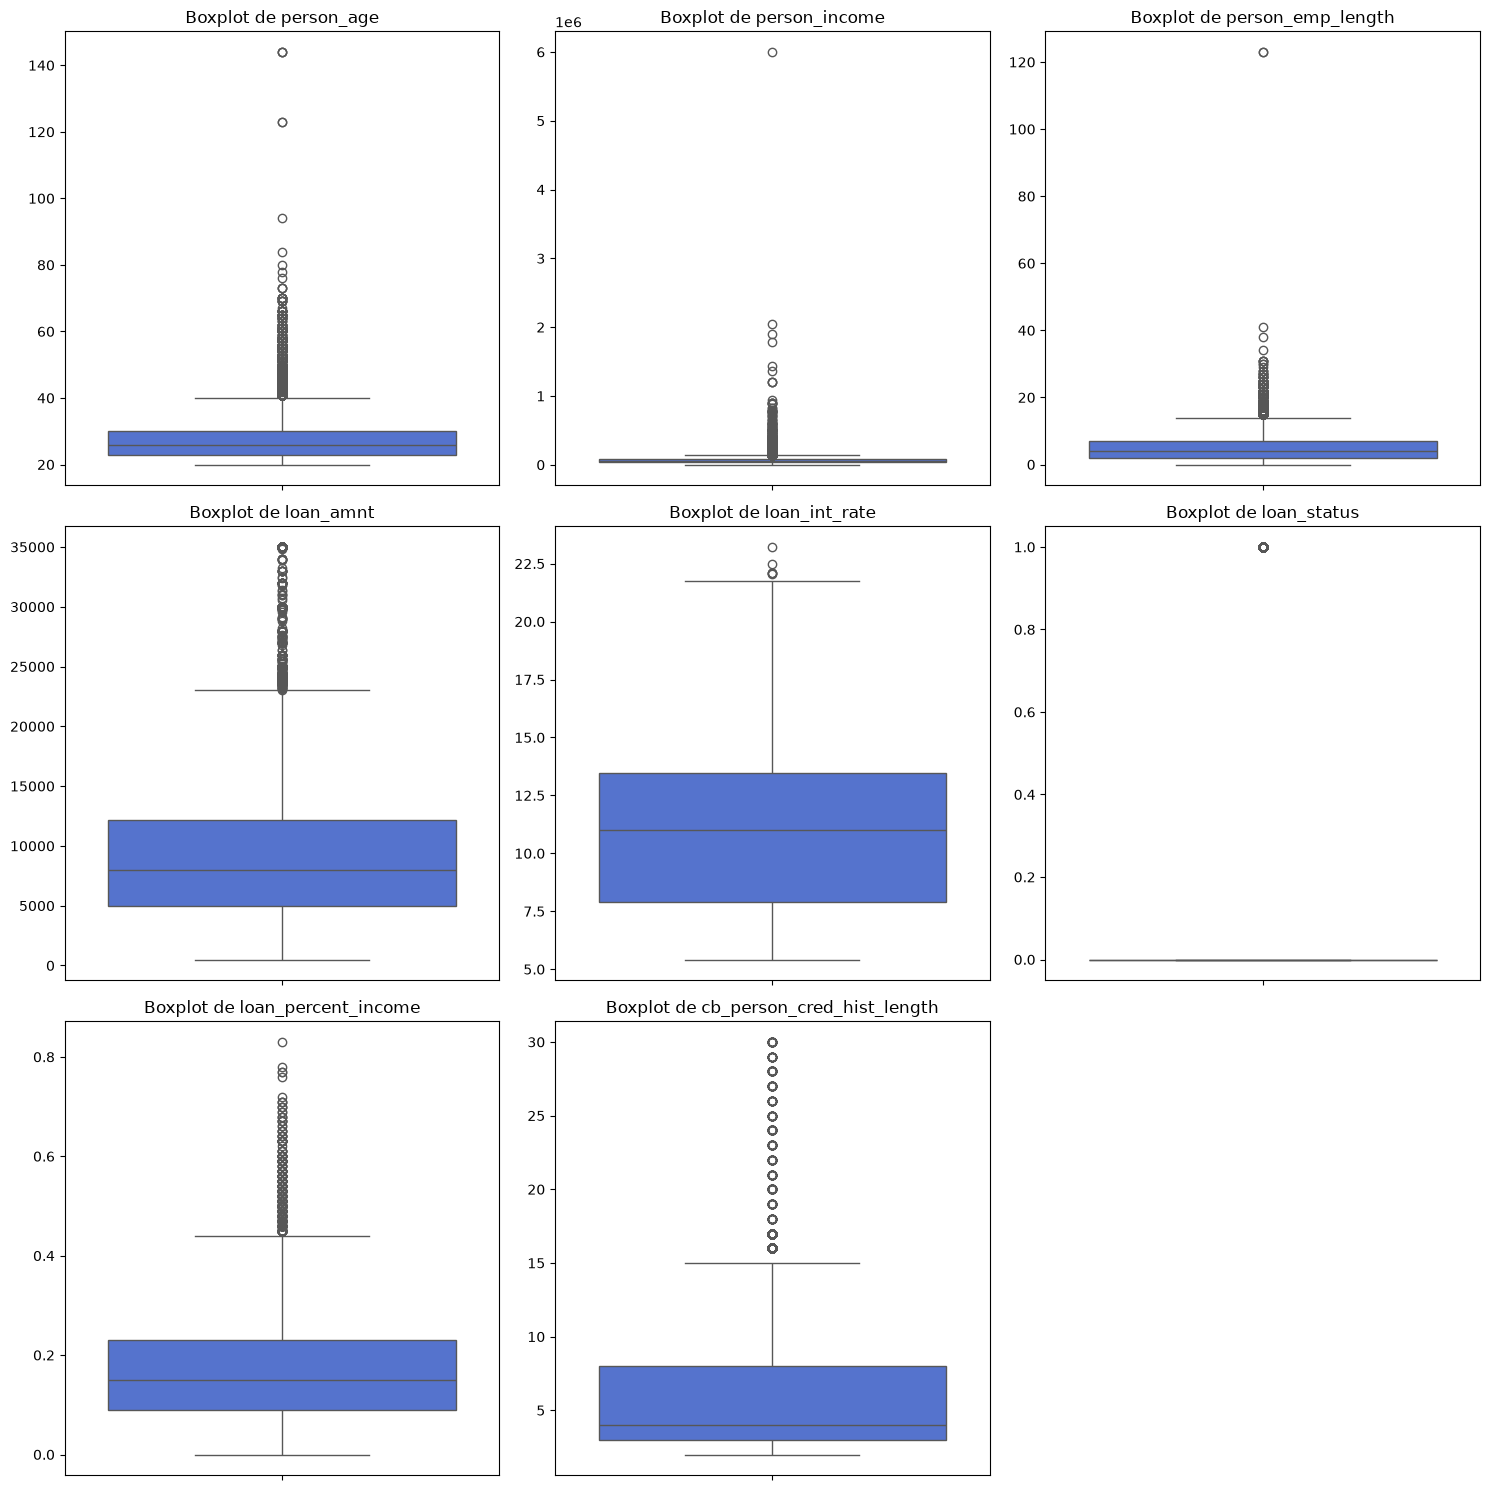

In [4]:
columnas_numericas = df.select_dtypes(include=[np.number]).columns

# 3. Calcular la disposición de la cuadrícula de gráficos (ej. 3 columnas)
num_variables = len(columnas_numericas)
num_filas = (num_variables + 2) // 3

# 4. Crear la figura y los subgráficos
fig, axes = plt.subplots(num_filas, 3, figsize=(15, 5 * num_filas))
axes = axes.flatten() # Aplanar el arreglo de ejes para iterar más fácil

# 5. Generar un boxplot para cada variable numérica
for i, col in enumerate(columnas_numericas):
    sns.boxplot(y=df[col], ax=axes[i], color='royalblue')
    axes[i].set_title(f'Boxplot de {col}')
    axes[i].set_ylabel('')

# 6. Ocultar los ejes vacíos si la cantidad de variables no es múltiplo de 3
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Ajustar el espacio y mostrar los gráficos
plt.tight_layout()
plt.show()